# PyLMM in practice: a guided tour

This notebook walks through a mixed-model GWAS with PyLMM the way a scientist would use it: simulate data
with a **known answer**, fit the model, run the scan, and learn to *read* the output correctly. Every
interpretation claim in the PyLMM agent skills (`skills/`) that this notebook touches is checked here with
numbers, so you can see it rather than take it on trust.

The model is

$$Y = X_0 b + x a + u + e,\qquad u \sim N(0,\, h\,\sigma^2 K),\quad e \sim N(0,\,(1-h)\,\sigma^2 I),$$

with a Wald *t* test of $a$ for each SNP $x$. $K$ is the kinship matrix, $h$ the heritability *on the scale of K*.

**Contents**
1. Simulate a related cohort with a known truth
2. Kinship and heritability
3. The scan, and the same scan from the command line
4. Reading the output: allele, scale, p-values
5. Is the scan calibrated? λ<sub>GC</sub>, QQ and thresholds
6. Making h² comparable across tools
7. Proximal contamination and LOCO
8. Three classic mistakes

In [1]:
import subprocess, sys, tempfile, os
from pathlib import Path
import numpy as np
from scipy import linalg, stats
import matplotlib.pyplot as plt

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "skills/convert-genotype-formats/scripts"))
sys.path.insert(0, str(REPO / "skills/interpret-gwas-results/scripts"))
import plink_tools, summarize_gwas
from pylmm.lmm import LMM, calculate_kinship, gwas
from pylmm.plink_io import PlinkReader

work = Path(tempfile.mkdtemp(prefix="pylmm_tour_")); os.chdir(work)   # scratch directory for files
rng = np.random.default_rng(2024)
print("working in", work)

working in /var/folders/jc/qwgzdqvd7b55x6rf6mbhpldr0000gn/T/pylmm_tour_g842k58h


## 1. Simulate a related cohort with a known truth

400 people in 80 families of 5 siblings, 3 chromosomes × 500 SNPs. The trait has

* an intercept 1 and a **sex** effect 0.5,
* **one causal SNP** (index 700, on chromosome 2) with an effect of **0.35 per SD** of its genotype,
* a polygenic part with $h^2 = 0.4$ drawn from the kinship, and independent noise.

Related people share genotypes *and* polygenic effects, so an ordinary regression would be miscalibrated;
that is what the mixed model is for.

In [2]:
n_fam, n_sib, m = 80, 5, 1500
p = rng.uniform(0.1, 0.5, m)
hap = rng.binomial(1, p, size=(n_fam, 4, m))                  # 4 parental haplotypes per family
G = np.concatenate([hap[:, rng.integers(0, 2)] + hap[:, 2 + rng.integers(0, 2)] for _ in range(n_sib)]).astype(float)
n = G.shape[0]                                                # G = copies of the A2 allele (0/1/2)
chrom = np.repeat(["1", "2", "3"], 500)
pos = np.tile(np.arange(1, 501) * 10_000, 3)
CAUSAL, H2_TRUE = 700, 0.4

sex = rng.integers(0, 2, n).astype(float)
Z = (G - G.mean(0)) / G.std(0)                                # standardised genotypes
K0 = calculate_kinship(G)
kva0, kve0 = linalg.eigh(K0)
u = kve0 @ (np.sqrt(np.clip(kva0, 0, None)) * rng.standard_normal(n)) * np.sqrt(H2_TRUE)
Y = 1 + 0.5 * sex + 0.35 * Z[:, CAUSAL] + u + rng.normal(scale=np.sqrt(1 - H2_TRUE), size=n)
print(n, "individuals,", m, "SNPs; var(Y) = %.2f" % Y.var())

400 individuals, 1500 SNPs; var(Y) = 1.26


## 2. Kinship and heritability

`calculate_kinship` standardises each SNP and returns $ZZ^\top/m$. The eigendecomposition is the
expensive step, so compute it once and pass it on.

**Always include the intercept in `X0`.** The library uses `X0` exactly as given; the command line adds it for you.

In [3]:
K = calculate_kinship(G)
kva, kve = linalg.eigh(K)
X0 = np.column_stack([np.ones(n), sex])          # intercept + sex
model = LMM(Y, K, kva, kve, X0=X0)
h, beta, s2, ll = model.fit()                    # REML (the default)
print("h2 = %.3f (truth %.2f)   sigma_g2 = %.3f   sigma_e2 = %.3f" % (h, H2_TRUE, h * s2, (1 - h) * s2))
print("fixed effects (intercept, sex):", np.round(beta.ravel(), 3), "  truth: 1, 0.5")

h2 = 0.412 (truth 0.40)   sigma_g2 = 0.498   sigma_e2 = 0.710
fixed effects (intercept, sex): [1.01  0.409]   truth: 1, 0.5


A single estimate is noisy; **report an interval**. The profile likelihood is the right tool, especially near
the boundaries 0 and 0.99 (the search grid stops at 0.99, so any true $h^2 \ge 0.98$ is reported as 0.99):

95% profile CI for h2: [0.29, 0.53]


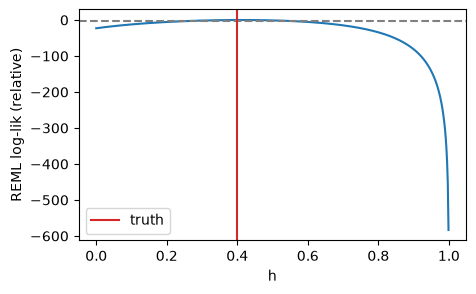

In [4]:
def profile_ci(model, level=0.95):
    grid = np.linspace(0, 0.999, 500)
    prof = np.array([model.log_likelihood(g).ll for g in grid])
    inside = grid[prof >= prof.max() - stats.chi2.ppf(level, 1) / 2]
    return grid, prof, inside.min(), inside.max()

grid, prof, lo, hi = profile_ci(model)
print("95%% profile CI for h2: [%.2f, %.2f]" % (lo, hi))
plt.figure(figsize=(5, 3)); plt.plot(grid, prof - prof.max()); plt.axhline(-1.92, ls="--", c="gray")
plt.axvline(H2_TRUE, c="C3", label="truth"); plt.xlabel("h"); plt.ylabel("REML log-lik (relative)"); plt.legend(); plt.show()

## 3. The scan, and the same scan from the command line

`gwas` returns arrays of *t* statistics and p-values. We write the data as PLINK files and check that the
`pylmm` command gives **the same numbers**; this is also the quickest way to validate any pipeline of your own.

In [5]:
iids = ["ind%d" % i for i in range(n)]
ids = [(i, i) for i in iids]
plink_tools.write_bed("cohort", G, iids=iids, chrom=chrom, pos=pos)
plink_tools.write_pheno("cohort.pheno", ids, Y, ["y"])
plink_tools.write_pheno("cohort.covar", ids, sex, ["sex"])        # no intercept column: the CLI adds it

ts, ps = gwas(Y, Z, K, kva, kve, X0=X0)
ts, ps = np.asarray(ts), np.asarray(ps)

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    assert r.returncode == 0, r.stderr
    return r.stderr
sh("pylmm kinship --bfile cohort -o cohort.kin")
log = sh("pylmm gwas --bfile cohort --kinship cohort.kin --pheno cohort.pheno --covar cohort.covar -o cohort.tsv -v")
print([l for l in log.splitlines() if "null model" in l or "individuals" in l])
res = summarize_gwas.read_results("cohort.tsv")
print("max |p_cli - p_lib| / p:", np.nanmax(np.abs(res["P_VALUE"] - ps) / ps))
print("lead SNP:", res["SNP_ID"][np.nanargmin(res["P_VALUE"])], " p = %.1e" % np.nanmin(res["P_VALUE"]), " (causal index %d)" % CAUSAL)

['pylmm: info: Read 400 individuals from cohort.fam', 'pylmm: info: Computing fit for null model', 'pylmm: info: null model: heritability=0.412, sigma=1.208']
max |p_cli - p_lib| / p: 1.5588020379642557e-07
lead SNP: snp701  p = 3.6e-07  (causal index 700)


## 4. Reading the output

| column | meaning |
|---|---|
| `BETA` | effect of the **A2** allele (`.bim` column 6), **per SD** of the standardised genotype |
| `BETA_SD` | the **standard error** of `BETA` (despite the name) |
| `F_STAT` | the signed Wald **t** = `BETA / BETA_SD` (not an F; F = t²) |
| `P_VALUE` | two-sided, from t with n − q − 1 degrees of freedom (q = columns of `X0`) |

Let us verify each claim, and convert to a per-allele effect, which is what other tools report.

In [6]:
i = CAUSAL
sd = G[:, i].std()                                       # SD of the 0/1/2 dosage
print("BETA per SD       : %.3f   (simulated effect per SD: 0.35)" % res["BETA"][i])
print("per copy of A2    : %.3f   (= BETA / sd, sd = %.3f)" % (res["BETA"][i] / sd, sd))
print("per copy of A1    : %.3f   (sign flipped; what plink2 / GEMMA / GCTA would call the effect allele)" % (-res["BETA"][i] / sd))
print("F_STAT == BETA/BETA_SD:", np.isclose(res["F_STAT"][i], res["BETA"][i] / res["BETA_SD"][i]))
df = n - X0.shape[1] - 1
print("p from t(df=%d): %.3e   reported: %.3e" % (df, 2 * stats.t.sf(abs(res["F_STAT"][i]), df), res["P_VALUE"][i]))

BETA per SD       : 0.347   (simulated effect per SD: 0.35)
per copy of A2    : 0.678   (= BETA / sd, sd = 0.512)
per copy of A1    : -0.678   (sign flipped; what plink2 / GEMMA / GCTA would call the effect allele)
F_STAT == BETA/BETA_SD: True
p from t(df=397): 3.646e-07   reported: 3.646e-07


**The allele is by position, not by name.** If you swap the roles of A1 and A2 in the files, the *same data*
gives the opposite sign of `BETA` and an identical p-value. Always read the `.bim` to know which allele is A2.
(For files written by plink2, A2 = REF, the opposite of plink2's own `--glm`.)

In [7]:
plink_tools.write_bed("flipped", 2 - G, iids=iids, chrom=chrom, pos=pos)     # same people, alleles swapped
sh("pylmm gwas --bfile flipped --kinship cohort.kin --pheno cohort.pheno --covar cohort.covar -o flipped.tsv")
fl = summarize_gwas.read_results("flipped.tsv")
print("BETA %.3f -> %.3f;  p %.2e -> %.2e" % (res["BETA"][i], fl["BETA"][i], res["P_VALUE"][i], fl["P_VALUE"][i]))

BETA 0.347 -> -0.347;  p 3.65e-07 -> 3.65e-07


## 5. Is the scan calibrated?

lambda_GC = 1.01   Bonferroni threshold = 3.3e-05


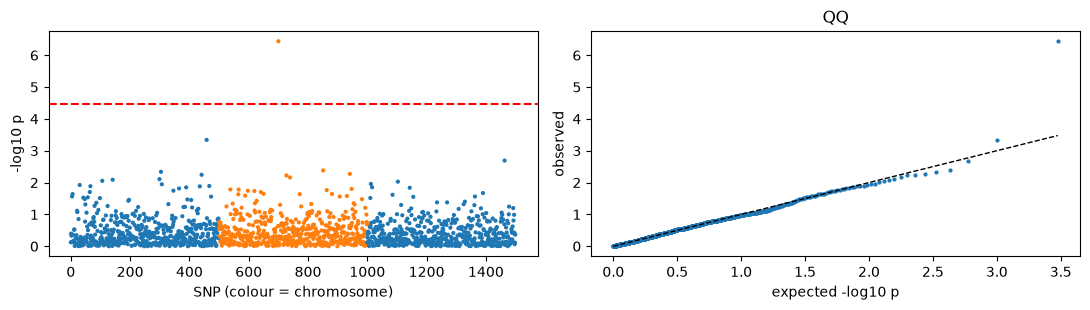

In [8]:
lam = summarize_gwas.lambda_gc(res["P_VALUE"])
bonf = 0.05 / np.sum(~np.isnan(res["P_VALUE"]))
print("lambda_GC = %.2f   Bonferroni threshold = %.1e" % (lam, bonf))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
x = np.arange(m)
ax[0].scatter(x, -np.log10(res["P_VALUE"]), s=4, c=np.where(chrom == "2", "C1", "C0"))
ax[0].axhline(-np.log10(bonf), c="r", ls="--"); ax[0].set_xlabel("SNP (colour = chromosome)"); ax[0].set_ylabel("-log10 p")
pv = np.sort(res["P_VALUE"][~np.isnan(res["P_VALUE"])])
exp = -np.log10((np.arange(1, len(pv) + 1) - 0.5) / len(pv))
ax[1].scatter(exp, -np.log10(pv), s=4); ax[1].plot([0, exp.max()], [0, exp.max()], "k--", lw=1)
ax[1].set_xlabel("expected -log10 p"); ax[1].set_ylabel("observed"); ax[1].set_title("QQ")
plt.tight_layout(); plt.show()

Read a QQ plot like this: a curve that departs **only in the tail** is signal; a curve lifted along its whole
length is inflation (missing covariate, K that does not match the samples). With few effective tests (small
panels, one chromosome, inbred strains) λ<sub>GC</sub> from a single scan is mostly noise.

**Related samples need an honest threshold.** Permuting `y` breaks the covariance the model assumes. Instead,
simulate phenotypes from the **fitted null model** and take the 5% quantile of the minimum p-value
(use ≥ 1000 replicates in real work; 100 here):

In [9]:
h0, b0, s20, _ = LMM(Y, K, kva, kve, X0=X0).fit()
min_p = []
for _ in range(100):
    u_b = kve @ (np.sqrt(np.clip(kva, 0, None)) * rng.standard_normal(n)) * np.sqrt(h0 * s20)
    y_b = (X0 @ b0).ravel() + u_b + rng.normal(scale=np.sqrt((1 - h0) * s20), size=n)
    min_p.append(np.nanmin(gwas(y_b, Z, K, kva, kve, X0=X0)[1]))
print("bootstrap threshold %.1e   vs Bonferroni %.1e" % (np.quantile(min_p, 0.05), bonf))

bootstrap threshold 5.1e-05   vs Bonferroni 3.3e-05


## 6. Making h² comparable across tools

`h` lives on the scale of K. Divide K by a constant $c$ and $h$ changes as $h_c = hc/(hc+1-h)$ while every
test statistic stays the same. So when you compare with a paper or another tool, put both on the same scale,
or report **PVE** $= hd/(hd+1-h)$ with $d$ the mean diagonal of K, which does not depend on the scale.

In [10]:
c = 2.0
h_c = LMM(Y, K / c, kva / c, kve, X0=X0).fit()[0]
print("h(K) = %.4f;  h(K/%g) fitted = %.4f;  formula = %.4f" % (h, c, h_c, h * c / (h * c + 1 - h)))
pve = lambda h, K: h * np.mean(np.diag(K)) / (h * np.mean(np.diag(K)) + 1 - h)
print("PVE: K  %.4f   K/%g %.4f   (same)" % (pve(h, K), c, pve(h_c, K / c)))

h(K) = 0.4119;  h(K/2) fitted = 0.5834;  formula = 0.5834
PVE: K  0.4119   K/2 0.4119   (same)


A GCTA-style GRM of **inbred** lines has mean diagonal ≈ 2 (1 + F, F ≈ 1) while PyLMM's is ≈ 1, so the same
data gives a smaller $h^2$ on the GCTA scale (0.5 → 0.33). That is a difference in *scaling*, not in the biology.

## 7. Proximal contamination and LOCO

If K is built from all SNPs it contains the tested SNP, which can absorb some of its own signal and cost
power. **Leave-one-chromosome-out (LOCO)** tests each chromosome with a K built from the *other* chromosomes:
$K_{-c} = (ZZ^\top - Z_cZ_c^\top)/(m - m_c)$.

In [11]:
ZZ = {c: Z[:, chrom == c] @ Z[:, chrom == c].T for c in np.unique(chrom)}
total = sum(ZZ.values())
p_loco = np.full(m, np.nan)
for c in ZZ:
    on = chrom == c
    K_c = (total - ZZ[c]) / (m - on.sum())
    p_loco[on] = gwas(Y, Z[:, on], K_c, X0=X0)[1]
print("causal SNP  -log10 p:  K from all SNPs %.2f   LOCO %.2f" % (-np.log10(ps[CAUSAL]), -np.log10(p_loco[CAUSAL])))
print("lambda_GC: all-SNP K %.2f   LOCO %.2f" % (summarize_gwas.lambda_gc(ps), summarize_gwas.lambda_gc(p_loco)))

causal SNP  -log10 p:  K from all SNPs 6.44   LOCO 7.08
lambda_GC: all-SNP K 1.01   LOCO 1.13


Here the effect is small, so the gain is modest; it grows with the polygenic signal and, dramatically, in
inbred panels with few distinct genotypes (see the `simulate-lmm-data` skill, section 6).

## 8. Three classic mistakes

**(a) Forgetting the intercept in `X0`.** With only the sex column the model has no intercept; the null fit and
the scan are both wrong.

In [12]:
bad = LMM(Y, K, kva, kve, X0=sex[:, None])
print("h2 with the intercept: %.2f   without: %.2f" % (h, bad.fit()[0]))
ps_bad = np.asarray(gwas(Y, Z, K, kva, kve, X0=sex[:, None])[1])
print("lambda_GC with intercept %.2f, without %.2f" % (summarize_gwas.lambda_gc(ps), summarize_gwas.lambda_gc(ps_bad)))

h2 with the intercept: 0.41   without: 0.14


lambda_GC with intercept 1.01, without 1.08


**(b) Matching individuals by row position.** PyLMM matches `(FID, IID)`. Shuffling the phenotype file does
not matter to the command line, but shuffling `Y` against `K` in your own code destroys the model. Check the
log line "individuals read / matched / dropped" with `-v`.

**(c) Trusting `h = 0.99` or `h = 0` at face value.** Those are boundary estimates: simulate a nearly fully
heritable trait and watch the cap.

In [13]:
u_hi = kve @ (np.sqrt(np.clip(kva, 0, None)) * rng.standard_normal(n))
y_hi = u_hi * np.sqrt(0.995) + rng.normal(scale=np.sqrt(0.005), size=n)
mh = LMM(y_hi, K, kva, kve); print("true h2 = 0.995  ->  reported %.2f (cap)" % mh.fit()[0])
_, _, lo2, hi2 = profile_ci(mh); print("profile CI: [%.2f, %.3f]  (open on the right: 'h2 >= %.2f')" % (lo2, hi2, lo2))

true h2 = 0.995  ->  reported 0.99 (cap)
profile CI: [0.99, 0.997]  (open on the right: 'h2 >= 0.99')


## Where next

* Run a real analysis: skill `run-gwas`; interpret it: `interpret-gwas-results`.
* Heritability scales, strain means, intervals: `estimate-heritability`.
* Ad-hoc analyses (subsets, conditional, interactions, many phenotypes): `custom-association-analysis`.
* Validate any pipeline on a known answer: `simulate-lmm-data`.